# Clustering de municipios y oportunidades

Explora el número de clusters con inercia y silhouette. Después, selecciona visualmente `k` en la celda indicada y ejecuta las celdas de resultados.

In [1]:
import io
import logging
import sys
from pathlib import Path

import boto3
import pandas as pd
from botocore.exceptions import BotoCoreError, ClientError
from IPython.display import display

working_directory = Path.cwd().resolve()
project_root = next(
    (
        path
        for path in (working_directory, *working_directory.parents)
        if (path / "src" / "procesado" / "tabla_oro.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("No se encontró la raíz del proyecto.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.common.storage import get_storage_settings, s3_uri_for
from src.modelo.modelo import (
    crear_modelo_kmeans,
    graficar_clusters_interactivo,
    graficar_metricas_kmeans,
    seleccionar_municipios_bajo_media_cluster,
)
from src.modelo.prepara_variables_modelo import (
    escalar_variables_modelo,
    seleccionar_variables_modelo,
    tasa_ponderada_de_competidores,
)
from src.procesado.common.paths import GOLD_TABLE_PATH

logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s: %(message)s")

## Cargar la tabla Gold

Si S3 está configurado, se intenta leer desde `gold/`; ante un fallo se usa el Parquet local si existe.

In [3]:
storage_settings = get_storage_settings()
gold_s3_uri = s3_uri_for(GOLD_TABLE_PATH.name, "gold")

if storage_settings.save_s3 and gold_s3_uri:
    bucket_and_key = gold_s3_uri.removeprefix("s3://").split("/", 1)
    client_options = (
        {"region_name": storage_settings.region_name}
        if storage_settings.region_name
        else {}
    )
    try:
        response = boto3.client("s3", **client_options).get_object(
            Bucket=bucket_and_key[0],
            Key=bucket_and_key[1],
        )
        with response["Body"] as body:
            gold_municipios = pd.read_parquet(io.BytesIO(body.read()))
        print(f"Gold cargada desde {gold_s3_uri}")
    except (BotoCoreError, ClientError) as error:
        if not GOLD_TABLE_PATH.is_file():
            raise RuntimeError(
                f"No se pudo leer {gold_s3_uri} y no existe copia local en "
                f"{GOLD_TABLE_PATH}."
            ) from error
        logging.getLogger(__name__).warning(
            "No se pudo leer Gold desde S3; se usará la copia local: %s",
            error,
        )
        gold_municipios = pd.read_parquet(GOLD_TABLE_PATH)
else:
    if not GOLD_TABLE_PATH.is_file():
        raise FileNotFoundError(
            f"No se encontró la tabla Gold local: {GOLD_TABLE_PATH}; "
            "configura S3 o genera Gold primero."
        )
    gold_municipios = pd.read_parquet(GOLD_TABLE_PATH)
    print(f"Gold cargada desde {GOLD_TABLE_PATH}")

print(f"Municipios en Gold: {len(gold_municipios)}")
display(gold_municipios.head())

Gold cargada desde C:\Users\fatima.d.villalba\OneDrive - Accenture\Desktop\repos\market-expansion-sot\data\processed\gold\tabla_oro_municipios_andalucia.parquet
Municipios en Gold: 785


,municipality_code,municipality_name,province_code,province,population_year,population_total,population_18_50,population_growth_start_year,population_growth_pct,income_year,mean_net_income_per_person,gyms_count,other_sports_facilities_count
0,04001,Abla,04,Almería,2025,1267,464,2021,0.555556,2024,12836,0,1
1,04002,Abrucena,04,Almería,2025,1235,442,2021,1.89769,2024,12565,0,0
2,04003,Adra,04,Almería,2025,25579,11849,2021,0.380661,2024,10965,6,9
3,04004,Albanchez,04,Almería,2025,684,174,2021,-5.0,2024,12885,0,0
4,04005,Alboloduy,04,Almería,2025,578,216,2021,-5.863192,2024,11848,0,0


## Preparar variables de clustering

Los municipios con alguna variable ausente se muestran y se excluyen solo del clustering; permanecen en la tabla Gold.

In [4]:
variables_modelo = seleccionar_variables_modelo(gold_municipios)
mascara_completa = variables_modelo.notna().all(axis=1)
municipios_excluidos = gold_municipios.loc[~mascara_completa].copy()

if not municipios_excluidos.empty:
    print(
        f"Se excluyen {len(municipios_excluidos)} municipios del clustering "
        "por variables incompletas:"
    )
    columnas_exclusion = [
        columna
        for columna in ("municipality_code", "municipality_name")
        if columna in municipios_excluidos.columns
    ]
    municipios_excluidos = municipios_excluidos.loc[:, columnas_exclusion].copy()
    municipios_excluidos["variables_ausentes"] = variables_modelo.loc[
        ~mascara_completa
    ].apply(lambda fila: ", ".join(fila.index[fila.isna()]), axis=1)
    display(municipios_excluidos)

municipios_modelo = gold_municipios.loc[mascara_completa].reset_index(drop=True)
variables_modelo = seleccionar_variables_modelo(municipios_modelo)
if len(municipios_modelo) < 3:
    raise ValueError("Se necesitan al menos tres municipios completos para clustering.")

variables_escaladas = escalar_variables_modelo(variables_modelo)
print(f"Municipios incluidos en el clustering: {len(municipios_modelo)}")
display(variables_escaladas.head())

Se excluyen 2 municipios del clustering por variables incompletas:


,municipality_code,municipality_name,variables_ausentes
24,04026,Benitagla,mean_net_income_per_person
425,21027,Cumbres de Enmedio,mean_net_income_per_person


Municipios incluidos en el clustering: 783


,population_18_50,mean_net_income_per_person,population_growth_pct
0,-0.246794,0.489929,-0.027404
1,-0.248063,0.285115,0.230460
2,0.409538,-0.924118,-0.061006
3,-0.263512,0.526961,-1.094789
4,-0.261091,-0.256773,-1.260634


## Explorar el número de clusters

Los gráficos son complementarios: busca el codo en la inercia y compara las puntuaciones silhouette. No hay un `k` universalmente correcto; elige uno razonable para los datos y el objetivo de negocio.

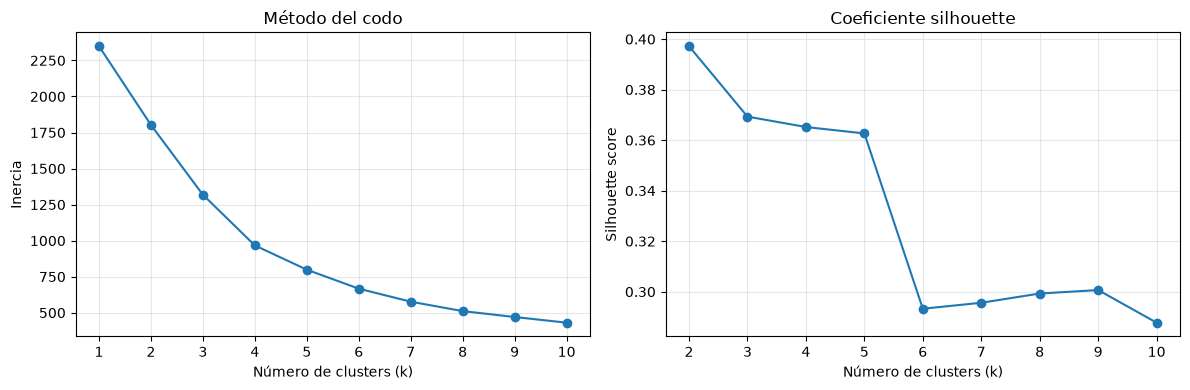

In [4]:
k_maximo = min(10, len(municipios_modelo) - 1)
k_inercia = range(1, k_maximo + 1)
k_silhouette = range(2, k_maximo + 1)

figura_metricas, ejes_metricas = graficar_metricas_kmeans(
    k_inercia,
    k_silhouette,
    variables_escaladas.to_numpy(),
)

## Elegir `k` y entrenar el modelo

Después de revisar los gráficos, cambia `N_CLUSTERS` por el valor elegido y ejecuta esta celda y las siguientes. Por ejemplo, si eliges cuatro grupos, asigna `N_CLUSTERS = 4`.

In [5]:
N_CLUSTERS = 4  # Sustituir por el k elegido tras revisar los gráficos.

if N_CLUSTERS is None:
    raise ValueError(
        "Elige N_CLUSTERS según los gráficos de inercia y silhouette "
        "y vuelve a ejecutar esta celda."
    )

modelo_kmeans = crear_modelo_kmeans(
    N_CLUSTERS,
    variables_escaladas.to_numpy(),
)
municipios_modelo["cluster"] = modelo_kmeans.labels_
print(f"Modelo entrenado con {N_CLUSTERS} clusters.")

Modelo entrenado con 4 clusters.


## Explorar los clusters de forma interactiva

La matriz compara las variables por pares e incluye todos los clusters. Para que los valores extremos no dominen los ejes, la visualización aplica una transformación asinh (lineal cerca de cero y comprimida en los extremos); KMeans sigue usando los valores estandarizados originales. Al pasar el cursor se muestran los valores estandarizados sin transformar.

In [6]:
figura_pares_clusters = graficar_clusters_interactivo(
    variables_escaladas,
    municipios_modelo,
    modelo_kmeans.labels_,
)
display(figura_pares_clusters)

# Perfil Clusters

In [7]:
resumen_clusters = municipios_modelo.copy()
cluster_profile = (
    resumen_clusters
      .groupby("cluster")
      .agg(
          municipios=("municipality_name", "count"),
          pob18_50_media=("population_18_50", "mean"),
          pob18_50_mediana=("population_18_50", "median"),
          renta_media=("mean_net_income_per_person", "mean"),
          crecimiento_medio=("population_growth_pct", "mean")
      )
      .round({
          "pob18_50_media": 0,
          "pob18_50_mediana": 0,
          "renta_media": 0,
          "crecimiento_medio": 2
      })
)
display(cluster_profile)

,municipios,pob18_50_media,pob18_50_mediana,renta_media,crecimiento_medio
cluster,,,,,
0,149,4809.0,1350.0,11968.0,8.57
1,453,2215.0,1013.0,11548.0,-1.44
2,3,229027.0,262785.0,15208.0,1.5
3,178,7349.0,791.0,13948.0,-0.47


Detectamos que ocurre en el cluster 1

In [ ]:

municipios_cluster_2 = municipios_modelo[municipios_modelo["cluster"] == 2]
display(municipios_cluster_2)

,municipality_code,municipality_name,province_code,province,population_year,population_total,population_18_50,population_growth_start_year,population_growth_pct,income_year,mean_net_income_per_person,gyms_count,other_sports_facilities_count,cluster
167,14021,Córdoba,14,Córdoba,2025,324159,132660,2021,0.568367,2024,14947,19,48,2
640,29067,Málaga,29,Málaga,2025,597173,262785,2021,3.305868,2024,14753,47,129,2
767,41091,Sevilla,41,Sevilla,2025,688714,291636,2021,0.639156,2024,15925,45,179,2


Vemos son grandes ciudades

## Seleccionar municipios candidatos

La tasa ponderada cuenta cada gimnasio como 1 instalación y cada otra instalación deportiva como 0,1, por cada 100.000 habitantes. Se seleccionan municipios estrictamente por debajo de la media de su propio cluster.

In [ ]:
# % candidatos
resumen_clusters["pct_candidatos"] = (
    resumen_clusters["municipios_candidatos"]
    / resumen_clusters["municipios_total"]
    * 100
).round(1)

tasa_media_competidores = tasa_ponderada_de_competidores(municipios_modelo)
candidatos = seleccionar_municipios_bajo_media_cluster(
    municipios_modelo,
    tasa_media_competidores,
)

# Fila TOTAL
fila_total = pd.DataFrame({
    "cluster": ["TOTAL"],
    "municipios_total": [resumen_clusters["municipios_total"].sum()],
    "tasa_media_competidores": ["N/A"],
    "municipios_candidatos": [resumen_clusters["municipios_candidatos"].sum()],
    "pct_candidatos": [round(
        resumen_clusters["municipios_candidatos"].sum()
        / resumen_clusters["municipios_total"].sum()
        * 100,
        1,
    )]
})

resumen_clusters = pd.concat(
    [resumen_clusters, fila_total],
    ignore_index=True,
)

display(resumen_clusters)

,cluster,municipios_total,tasa_media_competidores,municipios_candidatos,pct_candidatos
0,0,149,14.845498,113,75.8
1,1,453,15.492224,323,71.3
2,2,3,8.835211,1,33.3
3,3,178,21.9616,142,79.8
4,TOTAL,783,N/A,579,73.9


# Elejimos 5 mejores facturaciones

In [ ]:
ticket = 100
penetracion = 0.5
captacion = 0.5

In [ ]:
from src.negocio.calculos import calcular_potencial_mercado
municipios_candidatos = 